# 03 · Feature engineering

Preparamos as variáveis para o modelo aprender melhor:

1. tirar as casas de luxo (outliers);
2. logaritmo do preço e da área;
3. distância ao centro;
4. one-hot encoding (texto em colunas de 0 e 1);
5. escolher as variáveis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DADOS = Path("..") / "data"
df = pd.read_csv(DADOS / "processed" / "dados_limpos.csv")

## 1. Casas de luxo

As casas acima de 2,5 milhões de € são só 4% dos anúncios. Vemos onde ficam no histograma e comparamos o preço por m² com a caixa de bigodes (a caixa tem os 50% de casas do meio; os pontos isolados são valores extremos).

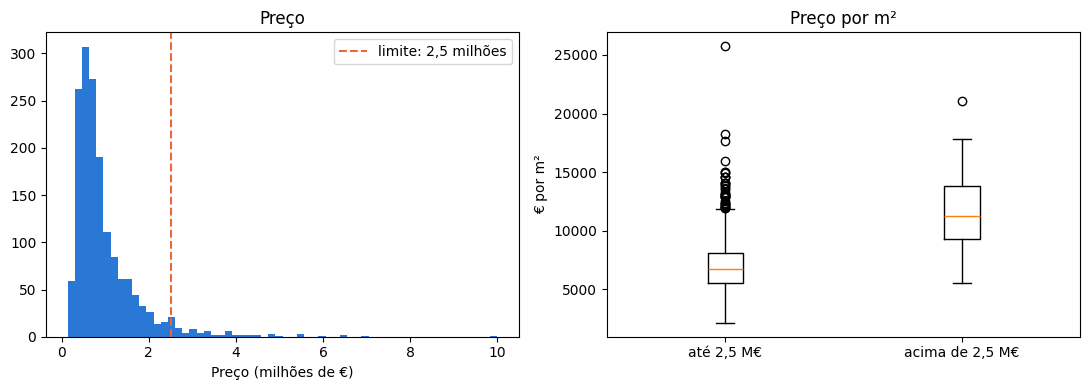

Casas de luxo: 70 (4.3%)
Preço mediano por m²: 6700 € (até 2,5 M€) vs 11229 € (luxo)


In [2]:
luxo = df["preco"] > 2_500_000   # True nas casas de luxo
m2 = df["preco"] / df["area_m2"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(df["preco"] / 1e6, bins=60, color="#2a78d6")
ax1.axvline(2.5, color="#eb6834", linestyle="--", label="limite: 2,5 milhões")
ax1.set_title("Preço")
ax1.set_xlabel("Preço (milhões de €)")
ax1.legend()

ax2.boxplot([m2[~luxo], m2[luxo]])   # ~luxo = "não é luxo"
ax2.set_xticks([1, 2], ["até 2,5 M€", "acima de 2,5 M€"])
ax2.set_title("Preço por m²")
ax2.set_ylabel("€ por m²")
plt.tight_layout()
plt.show()

print(f"Casas de luxo: {luxo.sum()} ({luxo.mean():.1%})")
print(f"Preço mediano por m²: {m2[~luxo].median():.0f} € (até 2,5 M€) vs {m2[luxo].median():.0f} € (luxo)")

O que vemos: as casas de luxo estão na cauda do histograma e são outro mercado: o m² é muito mais caro e varia muito mais (a caixa é mais alta). São poucas para o modelo aprender um padrão fiável, por isso ficam de fora. O modelo serve para casas até 2,5 milhões.

In [3]:
df = df[~luxo]   # ficam as casas que não são de luxo
print(f"Ficam {len(df)} anúncios")

Ficam 1553 anúncios


## 2. Logaritmo do preço e da área

O preço tem uma cauda longa. Com o logaritmo, uma subida de 300 para 600 mil € conta o mesmo que de 1 para 2 milhões (as duas são "o dobro"). Assim o modelo aprende em percentagens e as casas caras não dominam.

O logaritmo do preço é aplicado dentro do modelo (notebook 04). Aqui vemos o efeito:

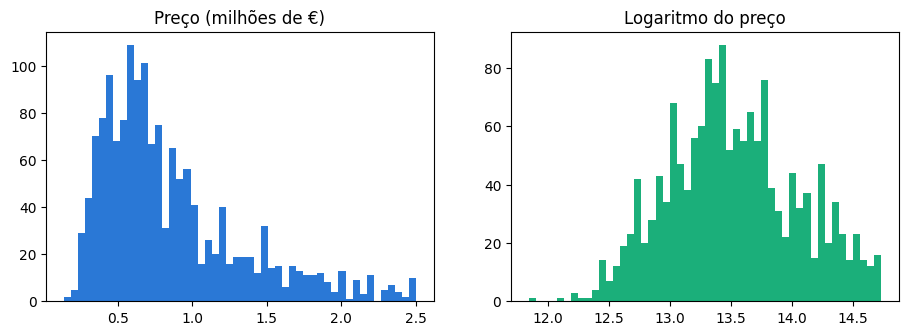

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.hist(df["preco"] / 1e6, bins=50, color="#2a78d6")
ax1.set_title("Preço (milhões de €)")
ax2.hist(np.log(df["preco"]), bins=50, color="#1baf7a")
ax2.set_title("Logaritmo do preço")
plt.show()

Com o logaritmo, a distribuição fica quase simétrica.

Fazemos o mesmo à área. A relação entre log(área) e log(preço) é mais próxima de uma linha reta, o que ajuda a regressão linear múltipla.

In [5]:
df["log_area"] = np.log(df["area_m2"])

print(f"Correlação área vs preço:           {df['area_m2'].corr(df['preco']):.2f}")
print(f"Correlação log(área) vs log(preço): {df['log_area'].corr(np.log(df['preco'])):.2f}")

Correlação área vs preço:           0.80
Correlação log(área) vs log(preço): 0.83


## 3. Distância ao centro

No notebook 02 vimos que o preço é mais alto no centro. Calculamos a distância em km a um ponto central, o Chiado, com o teorema de Pitágoras (1 grau de latitude são cerca de 110,6 km; 1 grau de longitude, em Lisboa, cerca de 87 km).

In [6]:
CENTRO_LAT, CENTRO_LON = 38.7107, -9.1433   # Chiado

dy = (df["latitude"] - CENTRO_LAT) * 110.57   # distância norte-sul, em km
dx = (df["longitude"] - CENTRO_LON) * 86.9    # distância este-oeste, em km
df["distancia_centro_km"] = np.sqrt(dx**2 + dy**2)

df["distancia_centro_km"].describe().round(1)

count    1553.0
mean        3.0
std         2.1
min         0.1
25%         1.4
50%         2.4
75%         4.4
max         9.9
Name: distancia_centro_km, dtype: float64

## 4. One-hot encoding

Os modelos só trabalham com números, mas a freguesia, o estado e o tipo são texto. O one-hot encoding transforma uma coluna de texto em várias colunas de 0 e 1, uma por categoria. Exemplo com 4 casas inventadas:

In [7]:
exemplo = pd.DataFrame({"estado": ["good", "renew", "newdevelopment", "good"]})

# get_dummies faz o one-hot encoding; dtype=int mostra 0 e 1 em vez de True e False
pd.concat([exemplo, pd.get_dummies(exemplo["estado"], dtype=int)], axis=1)

,estado,good,newdevelopment,renew
0,good,1,0,0
1,renew,0,0,1
2,newdevelopment,0,1,0
3,good,1,0,0


Cada linha é uma casa: tem 1 na coluna do seu estado e 0 nas outras.

Nos dados verdadeiros isto é feito dentro do modelo, no notebook 04 (com o `OneHotEncoder` do scikit-learn), para casas novas serem transformadas da mesma forma. A freguesia passa a 24 colunas, o estado a 3 e o tipo a 4.

## 5. Escolher as variáveis

- Ficam: log da área, quartos, casas de banho, andar, coordenadas, distância ao centro, freguesia, estado, tipo e os 8 extras.
- A área fica no ficheiro só para a regra simples do notebook 05 (no modelo entra o log da área).
- O preço é o que queremos prever.

O preço por m² não entra: é calculado com o preço, por isso o modelo estaria a ver a resposta.

In [8]:
colunas = ["log_area", "quartos", "casas_banho", "andar", "latitude", "longitude",
           "distancia_centro_km", "freguesia", "estado", "tipo",
           "elevador", "empreendimento_novo", "terraco", "piscina", "jardim",
           "ar_condicionado", "arrecadacao", "estacionamento",
           "area_m2", "preco"]

df[colunas].to_csv(DADOS / "processed" / "dados_modelo.csv", index=False)
print(f"Gravado: {len(df)} anúncios e {len(colunas)} colunas")

Gravado: 1553 anúncios e 20 colunas
